In [18]:
import pandas as pd

data = {
    "player":   ["Striker A", "Striker B", "Striker C", "Striker D", "Striker E", "Striker F"],
    "league":   ["EPL", "LaLiga", "Bundesliga", "EPL", "SerieA", "Ligue1"],
    "age":      [24, 31, 22, 27, 29, 20],
    "foot":     ["Left", "Right", "Right", "Right", "Left", "Right"],
    "minutes":  [2700, 2900, 1800, 2400, 2600, 300],
    "goals":    [20, 18, 12, 14, 15, 3],
    "xg":       [17.5, 19.2, 13.0, 10.1, 14.8, 1.2],
    "value_m":  [90, 35, 45, 60, 25, 15],   # 身价，单位：百万欧元
}

df = pd.DataFrame(data)
df["goals_p90"] = df["goals"] / df["minutes"] * 90
df["xg_p90"] = df["xg"] / df["minutes"] * 90
df["g_minus_xg"] = df["goals"] - df["xg"]
print(df)

      player      league  age   foot  minutes  goals    xg  value_m  \
0  Striker A         EPL   24   Left     2700     20  17.5       90   
1  Striker B      LaLiga   31  Right     2900     18  19.2       35   
2  Striker C  Bundesliga   22  Right     1800     12  13.0       45   
3  Striker D         EPL   27  Right     2400     14  10.1       60   
4  Striker E      SerieA   29   Left     2600     15  14.8       25   
5  Striker F      Ligue1   20  Right      300      3   1.2       15   

   goals_p90    xg_p90  g_minus_xg  
0   0.666667  0.583333         2.5  
1   0.558621  0.595862        -1.2  
2   0.600000  0.650000        -1.0  
3   0.525000  0.378750         3.9  
4   0.519231  0.512308         0.2  
5   0.900000  0.360000         1.8  


In [19]:
df.head()
df[["player", "goals"]]
df[(df["age"] <= 25) & (df["value_m"] <= 50)]
df.sort_values("goals_p90", ascending=False)
df[(df["age"] <= 28) & (df["value_m"] <= 50)]
df.sort_values("xg_p90", ascending=False)

,player,league,age,foot,minutes,goals,xg,value_m,goals_p90,xg_p90,g_minus_xg
2,Striker C,Bundesliga,22,Right,1800,12,13.0,45,0.600000,0.650000,-1.0
1,Striker B,LaLiga,31,Right,2900,18,19.2,35,0.558621,0.595862,-1.2
0,Striker A,EPL,24,Left,2700,20,17.5,90,0.666667,0.583333,2.5
4,Striker E,SerieA,29,Left,2600,15,14.8,25,0.519231,0.512308,0.2
3,Striker D,EPL,27,Right,2400,14,10.1,60,0.525000,0.378750,3.9
5,Striker F,Ligue1,20,Right,300,3,1.2,15,0.900000,0.360000,1.8


In [20]:
df[(df["age"] <= 28) & (df["value_m"] <= 50) & (df["minutes"] >= 900)]

,player,league,age,foot,minutes,goals,xg,value_m,goals_p90,xg_p90,g_minus_xg
2,Striker C,Bundesliga,22,Right,1800,12,13.0,45,0.6,0.65,-1.0


In [21]:
df.sort_values("g_minus_xg", ascending=False)

,player,league,age,foot,minutes,goals,xg,value_m,goals_p90,xg_p90,g_minus_xg
3,Striker D,EPL,27,Right,2400,14,10.1,60,0.525000,0.378750,3.9
0,Striker A,EPL,24,Left,2700,20,17.5,90,0.666667,0.583333,2.5
5,Striker F,Ligue1,20,Right,300,3,1.2,15,0.900000,0.360000,1.8
4,Striker E,SerieA,29,Left,2600,15,14.8,25,0.519231,0.512308,0.2
2,Striker C,Bundesliga,22,Right,1800,12,13.0,45,0.600000,0.650000,-1.0
1,Striker B,LaLiga,31,Right,2900,18,19.2,35,0.558621,0.595862,-1.2


In [22]:
# 模拟 Transfermarkt：身价资料
tm = pd.DataFrame({
    "player":  ["José Silva", "Ming-Hao Lee", "Tom Baker", "Luca Rossi"],
    "age":     [25, 23, 28, 30],
    "value_m": [40, 30, 55, 20],
})

# 模拟 Understat：表现资料
us = pd.DataFrame({
    "player":  ["Jose Silva", "Lee Ming-Hao", "Tom Baker", "Ali Hassan"],
    "minutes": [2500, 2000, 2700, 1500],
    "xg":      [12.0, 8.5, 15.2, 6.0],
})

inner = pd.merge(tm, us, on="player", how="inner")
display(inner)

left = pd.merge(tm, us, on="player", how="left")
display(left)

,player,age,value_m,minutes,xg
0,Tom Baker,28,55,2700,15.2


,player,age,value_m,minutes,xg
0,José Silva,25,40,NaN,NaN
1,Ming-Hao Lee,23,30,NaN,NaN
2,Tom Baker,28,55,2700.0,15.2
3,Luca Rossi,30,20,NaN,NaN


In [23]:
import re
import pandas as pd
from unidecode import unidecode
from rapidfuzz import process, fuzz

# ============================================================
# 1️⃣ 标准化函数
# ============================================================
def normalize_name(name):
    """José Silva → 'jose silva'；Lee Ming-Hao 和 Ming-Hao Lee → 'hao lee ming'"""
    if pd.isna(name):
        return ""
    name = unidecode(str(name)).lower()        # 去重音 + 小写
    name = re.sub(r"[^a-z\s]", " ", name)      # 去掉 - . ' 等符号
    parts = sorted(name.split())               # ✅ TODO 答案：排序，让顺序不再重要
    return " ".join(parts)

# 球会别名表：不同网站对同一球会的叫法不同，阶段 2 会持续扩充
TEAM_ALIASES = {
    "riverside utd": "riverside united",       # 示范用
    "man utd": "manchester united",
    "manchester utd": "manchester united",
    "spurs": "tottenham hotspur",
    "internazionale": "inter",
    "psg": "paris saint germain",
}

def normalize_team(team):
    if pd.isna(team):
        return ""
    t = unidecode(str(team)).lower()
    t = re.sub(r"[^a-z\s]", " ", t)                 # 去符号
    t = re.sub(r"\b(fc|cf|afc|ac|sc)\b", " ", t)    # 去掉 FC、AC 等后缀
    t = " ".join(t.split())
    return TEAM_ALIASES.get(t, t)

# ============================================================
# 2️⃣ 配对主函数
# ============================================================
def match_players(tm, us, threshold=85):
    tm = tm.copy()
    us = us.copy()
    tm["tm_id"] = range(len(tm))
    us["us_id"] = range(len(us))
    for df in (tm, us):
        df["name_key"] = df["player"].apply(normalize_name)
        df["team_key"] = df["team"].apply(normalize_team)

    # --- 第 1 层：名字 + 球会 完全相同 ---
    exact = pd.merge(
        tm[["tm_id", "name_key", "team_key"]],
        us[["us_id", "name_key", "team_key"]],
        on=["name_key", "team_key"],
    )
    # 同名又同队 → 一对多，无法自动判断，交给人工
    dup = exact["tm_id"].duplicated(keep=False) | exact["us_id"].duplicated(keep=False)
    ambiguous = exact[dup]
    exact = exact[~dup][["tm_id", "us_id"]].assign(method="exact", score=100.0)

    # --- 第 2 层：同球会内做模糊匹配 ---
    done_tm = set(exact["tm_id"]) | set(ambiguous["tm_id"])
    done_us = set(exact["us_id"]) | set(ambiguous["us_id"])
    tm_left = tm[~tm["tm_id"].isin(done_tm)]
    us_left = us[~us["us_id"].isin(done_us)]

    fuzzy_rows, used_us = [], set()
    for _, r in tm_left.iterrows():
        cands = us_left[(us_left["team_key"] == r["team_key"]) &
                        (~us_left["us_id"].isin(used_us))]
        if cands.empty:
            continue
        best = process.extractOne(
            r["name_key"],
            cands.set_index("us_id")["name_key"],
            scorer=fuzz.token_sort_ratio,
        )
        if best and best[1] >= threshold:
            used_us.add(best[2])
            fuzzy_rows.append({"tm_id": r["tm_id"], "us_id": best[2],
                               "method": "fuzzy", "score": round(best[1], 1)})
    fuzzy = pd.DataFrame(fuzzy_rows, columns=["tm_id", "us_id", "method", "score"])

    # --- 合并结果 ---
    links = pd.concat([exact, fuzzy], ignore_index=True)
    merged = (links.merge(tm, on="tm_id")
                   .merge(us, on="us_id", suffixes=("_tm", "_us")))

    unmatched_tm = tm[~tm["tm_id"].isin(links["tm_id"])]
    unmatched_us = us[~us["us_id"].isin(links["us_id"])]

    print(f"✅ exact: {len(exact)}  🔍 fuzzy: {len(fuzzy)}  "
          f"⚠️ ambiguous: {len(ambiguous)}  "
          f"❌ 未配对 TM: {len(unmatched_tm)} / US: {len(unmatched_us)}")
    return merged, unmatched_tm, unmatched_us, ambiguous

# ============================================================
# 3️⃣ 示范数据（⚠️ 全部虚构）
# ============================================================
tm = pd.DataFrame({
    "player":  ["José Silva", "Ming-Hao Lee", "Tom Baker", "Luca Rossi",
                "Danilo", "Danilo", "Mohamed Salaheddine"],
    "team":    ["Northbridge FC", "Riverside United", "Northbridge FC", "Lakeside AC",
                "Northbridge FC", "Riverside United", "Lakeside AC"],
    "age":     [25, 23, 28, 30, 30, 22, 26],
    "value_m": [40, 30, 55, 20, 18, 12, 35],
})

us = pd.DataFrame({
    "player":  ["Jose Silva", "Lee Ming-Hao", "Tom Baker", "Ali Hassan",
                "Danilo", "Danilo", "Mohammed Salaheddine"],
    "team":    ["Northbridge", "Riverside Utd", "Northbridge", "Lakeside",
                "Northbridge", "Riverside Utd", "Lakeside"],
    "minutes": [2500, 2000, 2700, 1500, 2100, 1300, 2200],
    "xg":      [12.0, 8.5, 15.2, 6.0, 3.1, 2.4, 9.7],
})

merged, unmatched_tm, unmatched_us, ambiguous = match_players(tm, us)

display(merged[["player_tm", "player_us", "team_tm", "method", "score",
                "age", "value_m", "minutes", "xg"]])
display(unmatched_tm[["player", "team"]])
display(unmatched_us[["player", "team"]])

✅ exact: 5  🔍 fuzzy: 1  ⚠️ ambiguous: 0  ❌ 未配对 TM: 1 / US: 1


,player_tm,player_us,team_tm,method,score,age,value_m,minutes,xg
0,José Silva,Jose Silva,Northbridge FC,exact,100.0,25,40,2500,12.0
1,Ming-Hao Lee,Lee Ming-Hao,Riverside United,exact,100.0,23,30,2000,8.5
2,Tom Baker,Tom Baker,Northbridge FC,exact,100.0,28,55,2700,15.2
3,Danilo,Danilo,Northbridge FC,exact,100.0,30,18,2100,3.1
4,Danilo,Danilo,Riverside United,exact,100.0,22,12,1300,2.4
5,Mohamed Salaheddine,Mohammed Salaheddine,Lakeside AC,fuzzy,97.4,26,35,2200,9.7


,player,team
3,Luca Rossi,Lakeside AC


,player,team
3,Ali Hassan,Lakeside


In [24]:
import pandas as pd

data = {
    "player":   ["Striker A", "Striker B", "Striker C", "Striker D", "Striker E", "Striker F"],
    "league":   ["EPL", "LaLiga", "Bundesliga", "EPL", "SerieA", "Ligue1"],
    "age":      [24, 31, 22, 27, 29, 20],
    "foot":     ["Left", "Right", "Right", "Right", "Left", "Right"],
    "minutes":  [2700, 2900, 1800, 2400, 2600, 300],
    "goals":    [20, 18, 12, 14, 15, 3],
    "xg":       [17.5, 19.2, 13.0, 10.1, 14.8, 1.2],
    "value_m":  [90, 35, 45, 60, 25, 15],
}
df = pd.DataFrame(data)

# 把文字列 league、foot 转成 0/1 的数字列
df_encoded = pd.get_dummies(df, columns=["league", "foot"], dtype=int)
display(df_encoded)

,player,age,minutes,goals,xg,value_m,league_Bundesliga,league_EPL,league_LaLiga,league_Ligue1,league_SerieA,foot_Left,foot_Right
0,Striker A,24,2700,20,17.5,90,0,1,0,0,0,1,0
1,Striker B,31,2900,18,19.2,35,0,0,1,0,0,0,1
2,Striker C,22,1800,12,13.0,45,1,0,0,0,0,0,1
3,Striker D,27,2400,14,10.1,60,0,1,0,0,0,0,1
4,Striker E,29,2600,15,14.8,25,0,0,0,0,1,1,0
5,Striker F,20,300,3,1.2,15,0,0,0,1,0,0,1


In [25]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

# ============ 1️⃣ 生成 200 名虚构球员 ============
rng = np.random.default_rng(42)          # 固定随机种子，每次结果相同
n = 200
leagues = ["EPL", "LaLiga", "Bundesliga", "SerieA", "Ligue1"]

df = pd.DataFrame({
    "age":     rng.integers(18, 35, n),
    "minutes": rng.integers(900, 3400, n),
    "xg_p90":  rng.uniform(0.1, 0.8, n).round(2),
    "league":  rng.choice(leagues, n),
    "foot":    rng.choice(["Left", "Right"], n, p=[0.3, 0.7]),
})

# 🤫 隐藏的“真实规律”（模型看不到这里）
league_bonus = {"EPL": 20, "LaLiga": 12, "Bundesliga": 10, "SerieA": 8, "Ligue1": 5}
df["value_m"] = (
    5
    + 70 * df["xg_p90"]
    + 0.005 * df["minutes"]
    - 1.5 * (df["age"] - 24)
    + df["league"].map(league_bonus)
    + rng.normal(0, 5, n)                 # 随机噪声：现实中的运气、经纪人等因素
).clip(lower=1).round(1)

# ============ 2️⃣ 准备 X（Features）和 y（Target）============
X = pd.get_dummies(df.drop(columns="value_m"), columns=["league", "foot"], dtype=int)
y = df["value_m"]

# ============ 3️⃣ 分割：80% 练习题，20% 期末考 ============
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# ============ 4️⃣ 训练模型 ============
model = LinearRegression()
model.fit(X_train, y_train)               # 👈 “学习”就在这一行

# ============ 5️⃣ 评估：练习题 vs 期末考 ============
for name, X_, y_ in [("Train", X_train, y_train), ("Test", X_test, y_test)]:
    pred = model.predict(X_)
    print(f"{name:5} → MAE: {mean_absolute_error(y_, pred):.2f}M   R²: {r2_score(y_, pred):.3f}")

# ============ 6️⃣ 模型学到的“计价公式” ============
coef = pd.Series(model.coef_, index=X.columns).round(3)
print("\n📋 模型学到的系数：")
print(coef)

# ============ 7️⃣ 抽 5 名测试球员，看预测 vs 实际 ============
sample = X_test.head(5).copy()
sample["actual"] = y_test.head(5).values
sample["predicted"] = model.predict(X_test.head(5)).round(1)
display(sample[["age", "minutes", "xg_p90", "actual", "predicted"]])

Train → MAE: 3.86M   R²: 0.932
Test  → MAE: 4.28M   R²: 0.878

📋 模型学到的系数：
age                  -1.447
minutes               0.006
xg_p90               69.024
league_Bundesliga    -2.259
league_EPL           10.224
league_LaLiga         1.015
league_Ligue1        -5.343
league_SerieA        -3.638
foot_Left            -0.303
foot_Right            0.303
dtype: float64


,age,minutes,xg_p90,actual,predicted
95,22,2201,0.73,71.7,76.5
15,31,1580,0.62,48.5,50.5
30,25,2058,0.20,39.5,40.0
158,26,1127,0.44,51.2,43.2
128,27,1253,0.54,49.1,52.5


Model                 Train MAE   Test MAE   Test R²
A: Linear                 5.49M      5.64M     0.707
B: Linear + age²          3.80M      4.27M     0.849
C: Random Forest          2.15M      6.18M     0.670


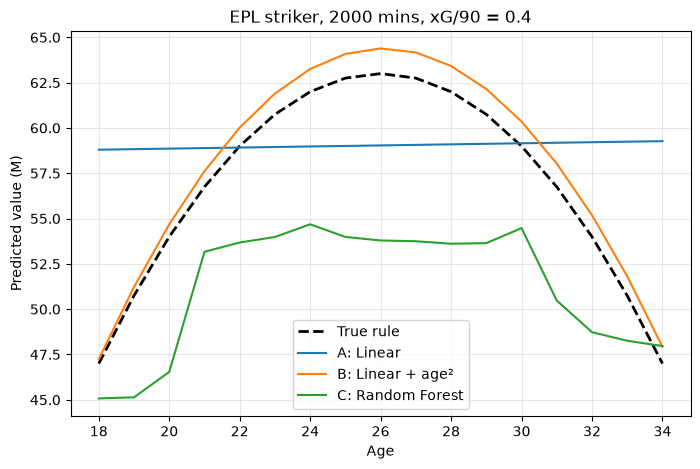

In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# ============ 1️⃣ 生成 200 名虚构球员（年龄改成山形）============
rng = np.random.default_rng(42)
n = 200
leagues = ["EPL", "LaLiga", "Bundesliga", "SerieA", "Ligue1"]

df = pd.DataFrame({
    "age":     rng.integers(18, 35, n),
    "minutes": rng.integers(900, 3400, n),
    "xg_p90":  rng.uniform(0.1, 0.8, n).round(2),
    "league":  rng.choice(leagues, n),
    "foot":    rng.choice(["Left", "Right", "Both"], n, p=[0.25, 0.65, 0.10]),
})

# 🤫 隐藏规律：26 岁是巅峰，越偏离 26 岁扣得越多（山形）
league_bonus = {"EPL": 20, "LaLiga": 12, "Bundesliga": 10, "SerieA": 8, "Ligue1": 5}
df["value_m"] = (
    5
    + 70 * df["xg_p90"]
    + 0.005 * df["minutes"]
    - 0.25 * (df["age"] - 26) ** 2        # ⛰️ 山形
    + df["league"].map(league_bonus)
    + rng.normal(0, 5, n)
).clip(lower=1).round(1)

# ============ 2️⃣ 准备特征（drop_first=True 避开虚拟变量陷阱）============
X = pd.get_dummies(df.drop(columns="value_m"), columns=["league", "foot"],
                   drop_first=True, dtype=int)
y = df["value_m"]

X2 = X.copy()
X2["age_sq"] = X2["age"] ** 2             # 参赛者 B 的秘密武器

idx_train, idx_test = train_test_split(X.index, test_size=0.2, random_state=42)

# ============ 3️⃣ 训练三位参赛者 ============
models = {
    "A: Linear":         (LinearRegression(), X),
    "B: Linear + age²":  (LinearRegression(), X2),
    "C: Random Forest":  (RandomForestRegressor(n_estimators=300, random_state=42), X),
}

print(f"{'Model':20} {'Train MAE':>10} {'Test MAE':>10} {'Test R²':>9}")
for name, (model, data) in models.items():
    model.fit(data.loc[idx_train], y.loc[idx_train])
    tr = mean_absolute_error(y.loc[idx_train], model.predict(data.loc[idx_train]))
    te_pred = model.predict(data.loc[idx_test])
    te = mean_absolute_error(y.loc[idx_test], te_pred)
    r2 = r2_score(y.loc[idx_test], te_pred)
    print(f"{name:20} {tr:>9.2f}M {te:>9.2f}M {r2:>9.3f}")

# ============ 4️⃣ 画图：固定其他条件，只改变年龄 ============
grid = pd.DataFrame({
    "age": np.arange(18, 35), "minutes": 2000, "xg_p90": 0.4,
    "league": "EPL", "foot": "Right",
})
G = pd.get_dummies(grid, columns=["league", "foot"], dtype=int) \
      .reindex(columns=X.columns, fill_value=0)
G2 = G.copy()
G2["age_sq"] = G2["age"] ** 2

true_curve = 5 + 70 * 0.4 + 0.005 * 2000 + 20 - 0.25 * (grid["age"] - 26) ** 2

plt.figure(figsize=(8, 5))
plt.plot(grid["age"], true_curve, "k--", lw=2, label="True rule")
plt.plot(grid["age"], models["A: Linear"][0].predict(G), label="A: Linear")
plt.plot(grid["age"], models["B: Linear + age²"][0].predict(G2), label="B: Linear + age²")
plt.plot(grid["age"], models["C: Random Forest"][0].predict(G), label="C: Random Forest")
plt.xlabel("Age")
plt.ylabel("Predicted value (M)")
plt.title("EPL striker, 2000 mins, xG/90 = 0.4")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Model                 Train MAE   Test MAE   Test R²
A: Linear                 5.49M      5.64M     0.707
B: Linear + age²          3.80M      4.27M     0.849
C: Random Forest          4.64M      5.83M     0.655


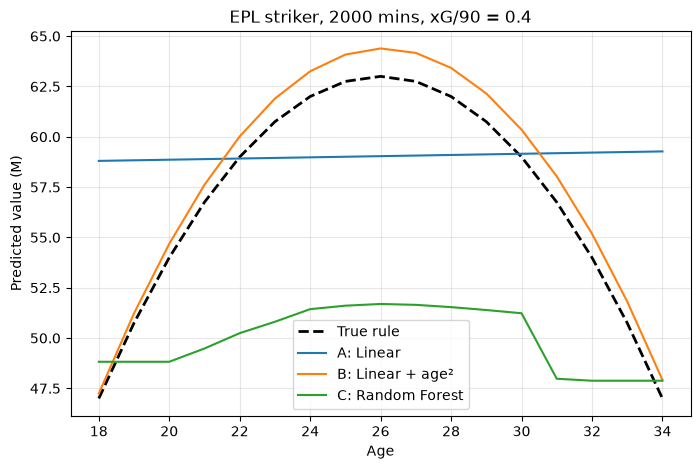

In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# ============ 1️⃣ 生成 200 名虚构球员（年龄改成山形）============
rng = np.random.default_rng(42)
n = 200
leagues = ["EPL", "LaLiga", "Bundesliga", "SerieA", "Ligue1"]

df = pd.DataFrame({
    "age":     rng.integers(18, 35, n),
    "minutes": rng.integers(900, 3400, n),
    "xg_p90":  rng.uniform(0.1, 0.8, n).round(2),
    "league":  rng.choice(leagues, n),
    "foot":    rng.choice(["Left", "Right", "Both"], n, p=[0.25, 0.65, 0.10]),
})

# 🤫 隐藏规律：26 岁是巅峰，越偏离 26 岁扣得越多（山形）
league_bonus = {"EPL": 20, "LaLiga": 12, "Bundesliga": 10, "SerieA": 8, "Ligue1": 5}
df["value_m"] = (
    5
    + 70 * df["xg_p90"]
    + 0.005 * df["minutes"]
    - 0.25 * (df["age"] - 26) ** 2        # ⛰️ 山形
    + df["league"].map(league_bonus)
    + rng.normal(0, 5, n)
).clip(lower=1).round(1)

# ============ 2️⃣ 准备特征（drop_first=True 避开虚拟变量陷阱）============
X = pd.get_dummies(df.drop(columns="value_m"), columns=["league", "foot"],
                   drop_first=True, dtype=int)
y = df["value_m"]

X2 = X.copy()
X2["age_sq"] = X2["age"] ** 2             # 参赛者 B 的秘密武器

idx_train, idx_test = train_test_split(X.index, test_size=0.2, random_state=42)

# ============ 3️⃣ 训练三位参赛者 ============
models = {
    "A: Linear":         (LinearRegression(), X),
    "B: Linear + age²":  (LinearRegression(), X2),
    "C: Random Forest":  (RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=42), X),
}

print(f"{'Model':20} {'Train MAE':>10} {'Test MAE':>10} {'Test R²':>9}")
for name, (model, data) in models.items():
    model.fit(data.loc[idx_train], y.loc[idx_train])
    tr = mean_absolute_error(y.loc[idx_train], model.predict(data.loc[idx_train]))
    te_pred = model.predict(data.loc[idx_test])
    te = mean_absolute_error(y.loc[idx_test], te_pred)
    r2 = r2_score(y.loc[idx_test], te_pred)
    print(f"{name:20} {tr:>9.2f}M {te:>9.2f}M {r2:>9.3f}")

# ============ 4️⃣ 画图：固定其他条件，只改变年龄 ============
grid = pd.DataFrame({
    "age": np.arange(18, 35), "minutes": 2000, "xg_p90": 0.4,
    "league": "EPL", "foot": "Right",
})
G = pd.get_dummies(grid, columns=["league", "foot"], dtype=int) \
      .reindex(columns=X.columns, fill_value=0)
G2 = G.copy()
G2["age_sq"] = G2["age"] ** 2

true_curve = 5 + 70 * 0.4 + 0.005 * 2000 + 20 - 0.25 * (grid["age"] - 26) ** 2

plt.figure(figsize=(8, 5))
plt.plot(grid["age"], true_curve, "k--", lw=2, label="True rule")
plt.plot(grid["age"], models["A: Linear"][0].predict(G), label="A: Linear")
plt.plot(grid["age"], models["B: Linear + age²"][0].predict(G2), label="B: Linear + age²")
plt.plot(grid["age"], models["C: Random Forest"][0].predict(G), label="C: Random Forest")
plt.xlabel("Age")
plt.ylabel("Predicted value (M)")
plt.title("EPL striker, 2000 mins, xG/90 = 0.4")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [28]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.metrics.pairwise import euclidean_distances

# 联赛里的 200 名球员（用来计算“正常范围”）
rng = np.random.default_rng(42)
league = pd.DataFrame({
    "minutes": rng.integers(900, 3400, 200),
    "xg_p90":  rng.uniform(0.1, 0.8, 200),
})

# 要比较的三名球员
trio = pd.DataFrame({
    "minutes": [2000, 2100, 2400],
    "xg_p90":  [0.20, 0.75, 0.22],
}, index=["A", "B", "C"])

# ① 直接用原始数字计算距离（越小 = 越像）
print("📏 原始数字的距离：")
display(pd.DataFrame(euclidean_distances(trio),
                     index=trio.index, columns=trio.index).round(2))

# ② 标准化：每个指标换算成“比联赛平均高或低几个标准差”
scaler = StandardScaler().fit(league)
trio_scaled = pd.DataFrame(scaler.transform(trio),
                           index=trio.index, columns=trio.columns)
print("🔄 标准化之后的数值：")
display(trio_scaled.round(2))

print("📏 标准化之后的距离：")
display(pd.DataFrame(euclidean_distances(trio_scaled),
                     index=trio.index, columns=trio.index).round(2))

📏 原始数字的距离：


,A,B,C
A,0.0,100.0,400.0
B,100.0,0.0,300.0
C,400.0,300.0,0.0


🔄 标准化之后的数值：


,minutes,xg_p90
A,-0.25,-1.15
B,-0.10,1.48
C,0.33,-1.06


📏 标准化之后的距离：


,A,B,C
A,0.00,2.64,0.59
B,2.64,0.00,2.58
C,0.59,2.58,0.00


In [29]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.metrics.pairwise import cosine_similarity

# ============ 实验 1：酱料比例 ============
small = np.array([[2, 1]])    # 小店：甜 2、辣 1
big   = np.array([[4, 2]])    # 大店：甜 4、辣 2
weird = np.array([[1, 2]])    # 怪店：甜 1、辣 2

print("小店 vs 大店:", cosine_similarity(small, big).round(3))
print("小店 vs 怪店:", cosine_similarity(small, weird).round(3))

# ============ 实验 2：200 名虚构球员（⚠️ 数据全部虚构）============
rng = np.random.default_rng(7)
n = 200
feats = ["xg_p90", "xa_p90", "interceptions_p90", "aerials_won_p90"]

# 三种位置的“典型风格”
profiles = {
    "FW": [0.45, 0.15, 0.4, 2.0],   # 前锋：xG 高、拦截少
    "MF": [0.15, 0.20, 1.2, 1.0],   # 中场：xA 高、拦截中等
    "DF": [0.05, 0.05, 1.8, 3.0],   # 后卫：拦截多、争顶多
}
pos = rng.choice(list(profiles), n)
base = np.array([profiles[p] for p in pos])
noise = rng.normal(0, 0.25, (n, 4)) * base          # 每个人有约 25% 的个人差异

df = pd.DataFrame((base + noise).clip(min=0).round(2), columns=feats)
df.insert(0, "player", [f"Player_{i:03d}" for i in range(n)])
df.insert(1, "position", pos)

# ① 先标准化（上一课学的）
Z = StandardScaler().fit_transform(df[feats])

# ② 选一名前锋当目标，计算他和所有人的 Cosine 相似度
target = df.index[df["position"] == "FW"][0]
df["similarity"] = cosine_similarity(Z[[target]], Z)[0].round(3)

print("\n🎯 目标球员：")
display(df.loc[[target]])

print("🔍 最像他的 5 名球员：")
display(df.drop(index=target).sort_values("similarity", ascending=False).head(5))

print("🙅 最不像他的 5 名球员：")
display(df.drop(index=target).sort_values("similarity").head(5))

小店 vs 大店: [[1.]]
小店 vs 怪店: [[0.8]]

🎯 目标球员：


,player,position,xg_p90,xa_p90,interceptions_p90,aerials_won_p90,similarity
7,Player_007,FW,0.55,0.08,0.48,1.58,1.0


🔍 最像他的 5 名球员：


,player,position,xg_p90,xa_p90,interceptions_p90,aerials_won_p90,similarity
41,Player_041,FW,0.47,0.11,0.45,1.66,0.981
109,Player_109,FW,0.46,0.10,0.34,1.85,0.968
81,Player_081,FW,0.56,0.10,0.51,2.17,0.963
25,Player_025,FW,0.62,0.10,0.49,2.25,0.953
66,Player_066,FW,0.46,0.09,0.44,1.03,0.950


🙅 最不像他的 5 名球员：


,player,position,xg_p90,xa_p90,interceptions_p90,aerials_won_p90,similarity
129,Player_129,MF,0.05,0.19,1.36,1.17,-0.707
120,Player_120,MF,0.14,0.21,1.72,1.40,-0.607
190,Player_190,MF,0.13,0.19,1.95,1.19,-0.586
57,Player_057,MF,0.11,0.22,1.80,0.94,-0.574
172,Player_172,MF,0.09,0.17,1.31,1.08,-0.572
